# Step 06: data reduction and feature preparation

This notebook reduces the engineered feature table to a small core set and prepares the inputs for the later models.

In [1]:
import json
import time
import warnings
import contextlib
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.stats import rankdata, skew, spearmanr
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, average_precision_score
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:.3f}")

SEED = 42
C_SEP, C_CTL = "#d1495b", "#2e86ab"
SUMMARY, SAVED = [], []
COUNTS = {"pass": 0, "fail": 0}


def log(text=""):
    print(text)
    SUMMARY.append(str(text))


def check(label, ok, detail=""):
    ok = bool(ok)
    COUNTS["pass" if ok else "fail"] += 1
    tail = f" ({detail})" if detail != "" else ""
    log(f"[{'PASS' if ok else 'FAIL'}] {label}{tail}")
    return ok


def expect(label, observed, expected, tol=0):
    return check(label, abs(observed - expected) <= tol, f"observed {observed}, expected {expected}")


@contextlib.contextmanager
def guarded(label):
    try:
        yield
    except Exception as e:
        check(label, False, f"{type(e).__name__}: {e}")


@contextlib.contextmanager
def timed(label):
    t0 = time.time()
    try:
        yield
    finally:
        log(f"{label}: {time.time() - t0:.1f} s")


def save_fig(name):
    plt.tight_layout()
    path = FIG / name
    plt.savefig(path, dpi=150)
    SAVED.append(path)
    plt.show()
    plt.close()


def need(*names):
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError("an earlier section failed, missing: " + ", ".join(missing))


def save_json(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=1)


def find_root():
    start = Path.cwd().resolve()
    for d in [start, *start.parents]:
        if (d / "dataset").is_dir():
            return d
    raise FileNotFoundError(f"no folder with a dataset directory above {start}")

/Users/harnoorkaur/Downloads/Sepsis_ml/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Setup and input checks

This section sets the paths and checks the step 01 to 05 outputs against the sizes I expect.

In [2]:
ROOT = find_root()
PROC = ROOT / "data" / "processed"
TAB = ROOT / "results" / "tables"
FIG = ROOT / "results" / "figures"
for p in (TAB, FIG):
    p.mkdir(parents=True, exist_ok=True)
FLAT = PROC / "features_flat.parquet"
RATE = PROC / "rate_features.parquet"
log(f"ROOT = {ROOT}")

with open(PROC / "column_groups.json") as f:
    groups = json.load(f)
with open(PROC / "feature_sets.json") as f:
    feature_sets = json.load(f)
TARGET = groups["target"] if isinstance(groups["target"], str) else groups["target"][0]
VITALS, LABS = groups["vitals"], groups["labs"]
VALUE_COLS = VITALS + LABS
ID_COLS = ["patient_id", "hospital", "hour", "split"]

pf = pq.ParquetFile(FLAT)
all_cols = pf.schema_arrow.names
feats = all_cols[4:-1]
expect("rows in features_flat", pf.metadata.num_rows, 1552210)
expect("columns in features_flat", len(all_cols), 244)
check("column order is ID_COLS + features + target", all_cols[:4] == ID_COLS and all_cols[-1] == TARGET)
check("feature count and set match feature_sets['all']", len(feats) == 239 and set(feats) == set(feature_sets["all"]))
check("value columns", len(VITALS) == 8 and len(LABS) == 26, f"{len(VITALS)} vitals, {len(LABS)} labs")

ids = pd.read_parquet(FLAT, columns=ID_COLS + [TARGET])
N_ROWS = len(ids)
split_arr = ids["split"].astype(str).to_numpy()
hour = ids["hour"].to_numpy()
y = ids[TARGET].to_numpy().astype(np.int8)
train_idx = np.flatnonzero(split_arr == "train")
val_idx = np.flatnonzero(split_arr == "val")
test_idx = np.flatnonzero(split_arr == "test")

expected_sizes = {"train": (28235, 1085958), "val": (6050, 234037), "test": (6051, 232215)}
n_pat = ids.groupby("split", observed=True)["patient_id"].nunique()
for name, (n_p, n_r) in expected_sizes.items():
    expect(f"{name} patients", int(n_pat[name]), n_p)
    expect(f"{name} rows", int((split_arr == name).sum()), n_r)
expect("positive rows", int(y.sum()), 27916)

sp = pd.read_csv(PROC / "patient_splits.csv", dtype={"patient_id": str})
sp_index = sp.set_index("patient_id")
row_split = ids["patient_id"].map(sp_index["split"]).astype(str).to_numpy()
row_fold = ids["patient_id"].map(sp_index["cv_fold"]).to_numpy()
check("patient_splits split agrees with split column", (row_split == split_arr).all())
fold_ok = ((row_fold == -1) == (split_arr == "test")).all() and np.isin(row_fold[split_arr != "test"], [0, 1, 2, 3, 4]).all()
check("cv_fold is -1 for test and 0 to 4 otherwise", fold_ok)

SEVEN = ["HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp"]
FORCED = SEVEN + ["sirs_count", "shock_index", "Age", "Gender"]
check("forced features exist", all(f in feats for f in FORCED), f"{len(FORCED)} forced")
rate_cols = [f"rate_{c}" for c in VALUE_COLS] + ["rate_labs"]
RATE_SET = set(rate_cols)
log(f"train rows {len(train_idx):,}, val rows {len(val_idx):,}, test rows {len(test_idx):,}")

ROOT = /Users/harnoorkaur/Downloads/Sepsis_ml
[PASS] rows in features_flat (observed 1552210, expected 1552210)
[PASS] columns in features_flat (observed 244, expected 244)
[PASS] column order is ID_COLS + features + target
[PASS] feature count and set match feature_sets['all']
[PASS] value columns (8 vitals, 26 labs)
[PASS] train patients (observed 28235, expected 28235)
[PASS] train rows (observed 1085958, expected 1085958)
[PASS] val patients (observed 6050, expected 6050)
[PASS] val rows (observed 234037, expected 234037)
[PASS] test patients (observed 6051, expected 6051)
[PASS] test rows (observed 232215, expected 232215)
[PASS] positive rows (observed 27916, expected 27916)
[PASS] patient_splits split agrees with split column
[PASS] cv_fold is -1 for test and 0 to 4 otherwise
[PASS] forced features exist (11 forced)
train rows 1,085,958, val rows 234,037, test rows 232,215


In [3]:
def take_cols(path, cols, rows=None, chunk=40):
    n_out = N_ROWS if rows is None else len(rows)
    out = np.empty((n_out, len(cols)), dtype=np.float32)
    for i in range(0, len(cols), chunk):
        part = cols[i:i + chunk]
        t = pq.read_table(path, columns=part)
        if rows is not None:
            t = t.take(pa.array(rows))
        out[:, i:i + len(part)] = t.to_pandas().to_numpy(dtype=np.float32)
        del t
    return out


def load_any(cols, rows=None):
    is_rate = np.array([c in RATE_SET for c in cols])
    out = np.empty((N_ROWS if rows is None else len(rows), len(cols)), dtype=np.float32)
    if (~is_rate).any():
        out[:, ~is_rate] = take_cols(FLAT, [c for c in cols if c not in RATE_SET], rows)
    if is_rate.any():
        out[:, is_rate] = take_cols(RATE, [c for c in cols if c in RATE_SET], rows)
    return out


def uni_auc(x, labels):
    x = np.asarray(x, dtype=np.float32)
    med = np.nanmedian(x) if np.isfinite(x).any() else 0.0
    x = np.where(np.isnan(x), med, x)
    a = roc_auc_score(labels, x)
    return max(a, 1 - a)


def sample_rows(n):
    rng = np.random.default_rng(SEED)
    return np.sort(rng.choice(train_idx, size=n, replace=False))


def fill_nan(X, med):
    return np.where(np.isnan(X), med, X).astype(np.float32)


def make_frame(arr, cols, rows=None):
    base = ids[ID_COLS + [TARGET]]
    if rows is not None:
        base = base.iloc[rows]
        arr = arr[rows]
    base = base.reset_index(drop=True)
    return pd.concat([base, pd.DataFrame(arr, columns=cols)], axis=1)

## Measurement-rate features

The cumulative counts grow with time in the ICU, so I divide them by the hours so far and check how much of their AUROC comes from time alone.

In [4]:
need("ids", "feats", "VALUE_COLS", "train_idx")
cnt_cols_v = [f"cnt_{c}" for c in VALUE_COLS]

with guarded("rate features file"):
    with timed("rate features"):
        cnt = take_cols(FLAT, cnt_cols_v + ["n_labs_so_far"])
        rates = (cnt / (hour.astype(np.float32) + 1)[:, None]).astype(np.float32)
        del cnt
        rate_df = pd.DataFrame(rates, columns=rate_cols)
        rate_df.insert(0, "hour", hour)
        rate_df.insert(0, "patient_id", ids["patient_id"].to_numpy())
        rate_df.to_parquet(RATE, index=False)
        del rate_df
        back = pd.read_parquet(RATE, columns=["patient_id", "hour"])
        check("rate rows aligned with features_flat",
              (back["patient_id"].to_numpy() == ids["patient_id"].to_numpy()).all() and (back["hour"].to_numpy() == hour).all())
        del back
        n_rate = len([c for c in pq.ParquetFile(RATE).schema_arrow.names if c not in ("patient_id", "hour")])
        expect("rate columns", n_rate, 35)
        check("per-variable rates in [0, 1]", rates[:, :34].min() >= 0 and rates[:, :34].max() <= 1 + 1e-6,
              f"min {rates[:, :34].min():.3f}, max {rates[:, :34].max():.3f}")
        check("rate_labs in [0, 26]", rates[:, 34].min() >= 0 and rates[:, 34].max() <= 26 + 1e-4,
              f"min {rates[:, 34].min():.3f}, max {rates[:, 34].max():.3f}")
        check("no NaN in rate features", not np.isnan(rates).any())
        del rates

[PASS] rate rows aligned with features_flat
[PASS] rate columns (observed 35, expected 35)
[PASS] per-variable rates in [0, 1] (min 0.000, max 1.000)
[PASS] rate_labs in [0, 26] (min 0.000, max 25.000)
[PASS] no NaN in rate features
rate features: 1.3 s


AUROC ICULOS 0.630, hour 0.631, n_labs_so_far 0.673, rate_labs 0.588
      feature  auc_count  auc_rate  auc_iculos
0          HR      0.634     0.538       0.630
1       O2Sat      0.635     0.536       0.630
2        Temp      0.616     0.527       0.630
3         SBP      0.612     0.506       0.630
4         MAP      0.636     0.544       0.630
5         DBP      0.604     0.509       0.630
6        Resp      0.628     0.529       0.630
7       EtCO2      0.545     0.544       0.630
8  BaseExcess      0.609     0.582       0.630
9        HCO3      0.602     0.559       0.630
  bin  n_rows  n_pos  auc_n_labs_so_far  auc_rate_labs  auc_iculos
  0-5   46800    682              0.554          0.545       0.524
 6-11   46399    788              0.572          0.584       0.558
12-23   82135    839              0.599          0.603       0.523
24-47   98629    980              0.653          0.644       0.554
  48+   26037   2105              0.632          0.577       0.631
34 of 34 var

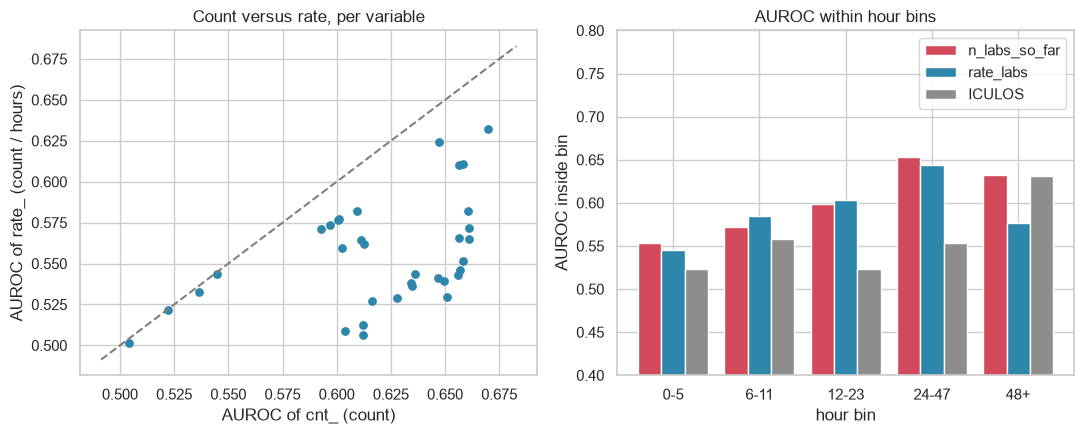

time-confound analysis: 2.5 s


In [5]:
ROWS300 = sample_rows(300000)
ys = y[ROWS300]
hs = hour[ROWS300]

with guarded("time-confound analysis"):
    with timed("time-confound analysis"):
        Xs = take_cols(FLAT, ["ICULOS", "n_labs_so_far"] + cnt_cols_v, ROWS300)
        Rs = take_cols(RATE, rate_cols, ROWS300)
        a_iculos = uni_auc(Xs[:, 0], ys)
        a_hour = uni_auc(hs, ys)
        a_nl = uni_auc(Xs[:, 1], ys)
        a_rl = uni_auc(Rs[:, 34], ys)
        log(f"AUROC ICULOS {a_iculos:.3f}, hour {a_hour:.3f}, n_labs_so_far {a_nl:.3f}, rate_labs {a_rl:.3f}")

        rate_auc = {}
        rows_out = []
        for k, c in enumerate(VALUE_COLS):
            ac, ar = uni_auc(Xs[:, 2 + k], ys), uni_auc(Rs[:, k], ys)
            rate_auc[f"rate_{c}"] = ar
            rows_out.append({"feature": c, "auc_count": ac, "auc_rate": ar, "auc_iculos": a_iculos})
        rate_auc["rate_labs"] = a_rl
        rate_cmp = pd.DataFrame(rows_out)
        rate_cmp.loc[len(rate_cmp)] = ["n_labs_so_far", a_nl, a_rl, a_iculos]
        rate_cmp.to_csv(TAB / "rate_vs_count_auroc.csv", index=False)
        print(rate_cmp.head(10))

        bin_id = np.digitize(hs, [6, 12, 24, 48])
        bin_names = ["0-5", "6-11", "12-23", "24-47", "48+"]
        bin_rows = []
        for b, name in enumerate(bin_names):
            m = bin_id == b
            n_pos = int(ys[m].sum())
            row = {"bin": name, "n_rows": int(m.sum()), "n_pos": n_pos,
                   "auc_n_labs_so_far": np.nan, "auc_rate_labs": np.nan, "auc_iculos": np.nan}
            if n_pos >= 50:
                row["auc_n_labs_so_far"] = uni_auc(Xs[m, 1], ys[m])
                row["auc_rate_labs"] = uni_auc(Rs[m, 34], ys[m])
                row["auc_iculos"] = uni_auc(Xs[m, 0], ys[m])
            bin_rows.append(row)
        bins_df = pd.DataFrame(bin_rows)
        bins_df.to_csv(TAB / "count_vs_rate_by_hour_bin.csv", index=False)
        print(bins_df.to_string(index=False))

        n_lose = int((rate_cmp["auc_rate"][:34] < rate_cmp["auc_count"][:34]).sum())
        within = ", ".join(f"{n} {v:.3f}" for n, v in zip(bins_df["bin"], bins_df["auc_n_labs_so_far"]))
        log(f"{n_lose} of 34 variables lose AUROC when count is replaced by rate; n_labs_so_far pooled {a_nl:.3f}, within hour bins: {within}")

        fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
        ax = axes[0]
        ax.scatter(rate_cmp["auc_count"][:34], rate_cmp["auc_rate"][:34], color=C_CTL, s=28)
        lo = min(rate_cmp["auc_count"].min(), rate_cmp["auc_rate"].min()) - 0.01
        hi = max(rate_cmp["auc_count"].max(), rate_cmp["auc_rate"].max()) + 0.01
        ax.plot([lo, hi], [lo, hi], color="grey", linestyle="--")
        ax.set_xlabel("AUROC of cnt_ (count)")
        ax.set_ylabel("AUROC of rate_ (count / hours)")
        ax.set_title("Count versus rate, per variable")
        ax = axes[1]
        x = np.arange(len(bins_df))
        w = 0.27
        series = [("auc_n_labs_so_far", "n_labs_so_far", C_SEP), ("auc_rate_labs", "rate_labs", C_CTL), ("auc_iculos", "ICULOS", "#8d8d8d")]
        for k, (col, lab, colr) in enumerate(series):
            ax.bar(x + (k - 1) * w, bins_df[col], w, label=lab, color=colr)
        ax.set_xticks(x)
        ax.set_xticklabels(bins_df["bin"])
        ax.set_ylim(0.4, 0.8)
        ax.set_xlabel("hour bin")
        ax.set_ylabel("AUROC inside bin")
        ax.set_title("AUROC within hour bins")
        ax.legend()
        save_fig("fig06_count_vs_rate.png")
        del Xs, Rs

## Redundancy filter

The forced features come first, then the rest by univariate AUROC, and a feature is dropped when it is almost a copy of one already kept.

[PASS] univariate AUROC table covers all 239 features


ranks: 100%|██████████| 274/274 [00:02<00:00, 98.98it/s] 


spearman matrix: 5.0 s
filter kept 200 of 274 candidates, dropped 74
          dropped   group   kept_partner   rho
0   cnt_Potassium   count  n_labs_so_far 0.910
1  cnt_Creatinine   count        cnt_BUN 0.958
2          cnt_pH   count      cnt_PaCO2 0.981
3   cnt_Platelets   count        cnt_WBC 0.935
4         cnt_Hgb   count        cnt_WBC 0.938
5       cnt_O2Sat   count        cnt_MAP 0.986
6          cnt_HR   count        cnt_MAP 0.993
7       rate_FiO2    rate       cnt_FiO2 0.954
8          ICULOS  static        cnt_MAP 0.964
9        cnt_Resp   count        cnt_MAP 0.969
          group  n_before  n_after
          value        34       29
           mask        34       28
     time_since        34       20
          count        34       22
missingness_agg         3        3
        rolling        64       45
          trend         8        8
       clinical         8        8
        extreme        13       13
         static         7        6
           rate        35    

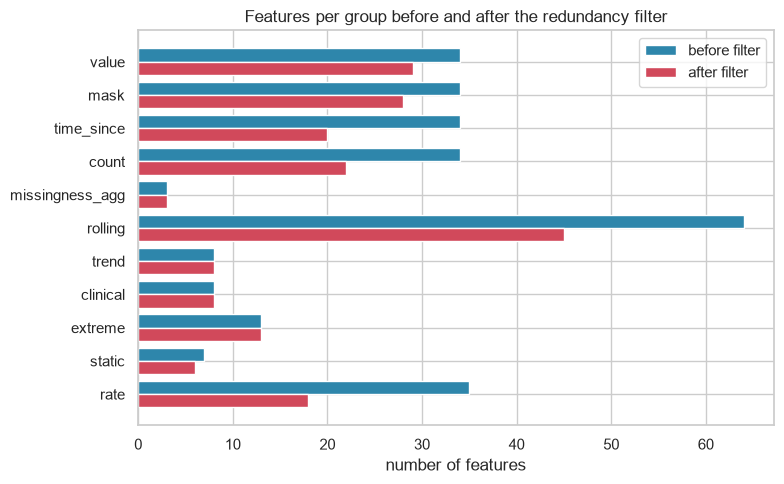

In [6]:
need("rate_auc", "feats", "FORCED", "train_idx")
uni = pd.read_csv(TAB / "univariate_auroc_train.csv")
gmap = dict(zip(uni["feature"], uni["group"]))
amap = dict(zip(uni["feature"], uni["auc"]))
check("univariate AUROC table covers all 239 features", all(f in amap for f in feats))
for r in rate_cols:
    gmap[r] = "rate"
    amap[r] = rate_auc[r]
pool_all = feats + rate_cols
pidx = {f: i for i, f in enumerate(pool_all)}
FORCED_SET = set(FORCED)

with guarded("redundancy filter"):
    with timed("spearman matrix"):
        rows200 = sample_rows(200000)
        X = load_any(pool_all, rows200)
        med = np.nanmedian(X, axis=0)
        med = np.where(np.isnan(med), 0, med).astype(np.float32)
        for j in range(X.shape[1]):
            col = X[:, j]
            col[np.isnan(col)] = med[j]
        R = np.empty_like(X)
        for j in tqdm(range(X.shape[1]), desc="ranks"):
            R[:, j] = rankdata(X[:, j])
        del X
        C = np.nan_to_num(np.corrcoef(R, rowvar=False), nan=0.0)
        np.fill_diagonal(C, 1.0)
        del R
        pd.DataFrame(C.round(3), index=pool_all, columns=pool_all).to_csv(TAB / "correlation_spearman_features.csv", index_label="feature")

    others = sorted([f for f in pool_all if f not in FORCED_SET], key=lambda f: (-amap[f], f))
    order = FORCED + others
    kept, drops = [], []
    for f in order:
        j = pidx[f]
        if f in FORCED_SET or not kept:
            kept.append(f)
            continue
        kj = np.array([pidx[k] for k in kept])
        rhos = np.abs(C[j, kj])
        top = int(rhos.argmax())
        if rhos[top] > 0.90:
            drops.append({"dropped": f, "group": gmap[f], "kept_partner": kept[top], "rho": round(float(C[j, kj[top]]), 3)})
        else:
            kept.append(f)
    drops_df = pd.DataFrame(drops)
    drops_df.to_csv(TAB / "redundancy_drops.csv", index=False)
    filtered = [f for f in pool_all if f in set(kept)]
    save_json(filtered, PROC / "filtered_features.json")
    log(f"filter kept {len(filtered)} of {len(pool_all)} candidates, dropped {len(drops_df)}")
    print(drops_df.head(10))

    group_order = ["value", "mask", "time_since", "count", "missingness_agg", "rolling", "trend", "clinical", "extreme", "static", "rate"]
    before = pd.Series([gmap[f] for f in pool_all]).value_counts()
    after = pd.Series([gmap[f] for f in filtered]).value_counts()
    gc = pd.DataFrame({"group": group_order})
    gc["n_before"] = gc["group"].map(before).fillna(0).astype(int)
    gc["n_after"] = gc["group"].map(after).fillna(0).astype(int)
    gc.to_csv(TAB / "feature_group_counts_by_stage.csv", index=False)
    print(gc.to_string(index=False))

    if "Hgb" in pidx and "Hct" in pidx:
        log(f"Spearman Hgb-Hct {C[pidx['Hgb'], pidx['Hct']]:.3f}")
    if "MAP" in pidx and "DBP" in pidx:
        log(f"Spearman MAP-DBP {C[pidx['MAP'], pidx['DBP']]:.3f}")
    fj = [pidx[f] for f in FORCED]
    pairs = [(FORCED[a], FORCED[b], C[fj[a], fj[b]]) for a in range(len(fj)) for b in range(a + 1, len(fj)) if abs(C[fj[a], fj[b]]) > 0.90]
    log("forced pairs above 0.90: " + (", ".join(f"{a}-{b} {r:.3f}" for a, b, r in pairs) if pairs else "none"))

    nf = [pidx[f] for f in filtered if f not in FORCED_SET]
    sub_c = np.abs(C[np.ix_(nf, nf)])
    np.fill_diagonal(sub_c, 0)
    check("no kept non-forced pair above 0.90", sub_c.max() <= 0.90, f"max {sub_c.max():.3f}")

    fig, ax = plt.subplots(figsize=(8, 5))
    pos = np.arange(len(gc))
    ax.barh(pos - 0.2, gc["n_before"], 0.4, color=C_CTL, label="before filter")
    ax.barh(pos + 0.2, gc["n_after"], 0.4, color=C_SEP, label="after filter")
    ax.set_yticks(pos)
    ax.set_yticklabels(gc["group"])
    ax.invert_yaxis()
    ax.set_xlabel("number of features")
    ax.set_title("Features per group before and after the redundancy filter")
    ax.legend()
    save_fig("fig06_group_counts.png")
    del C

## Core feature set

A random forest on the filtered pool gives an importance score, which is averaged in rank with the univariate AUROC to pick 50 features.

Validation rows are used in this section only to report the pool versus core comparison, and nothing in the selection depends on them.

pool random forest: 36.6 s
Spearman between AUROC rank and RF rank: 0.581
core set by group: count 13, value 9, extreme 8, rolling 8, time_since 6, missingness_agg 2, clinical 2, static 2
ICULOS: filtered out
HospAdmTime: not selected
unit_1: not selected
unit_2: not selected
unit_unknown: not selected
cnt_ features selected: ['cnt_MAP', 'cnt_WBC', 'cnt_BUN', 'cnt_Phosphate', 'cnt_FiO2', 'cnt_Lactate', 'cnt_DBP', 'cnt_Calcium', 'cnt_Magnesium', 'cnt_Temp', 'cnt_PaCO2', 'cnt_Hct', 'cnt_Chloride']
rate_ features selected: []
            feature            group   auc  rf_importance  rank_auc  rank_rf  \
0           cnt_MAP            count 0.636          0.040    13.000    1.000   
1     n_labs_so_far  missingness_agg 0.673          0.014     1.000   14.000   
2           cnt_WBC            count 0.657          0.017     8.000    8.000   
3   Temp_max_so_far          extreme 0.651          0.017     9.000   10.000   
4          FiO2_tsl       time_since 0.620          0.030    16.000    

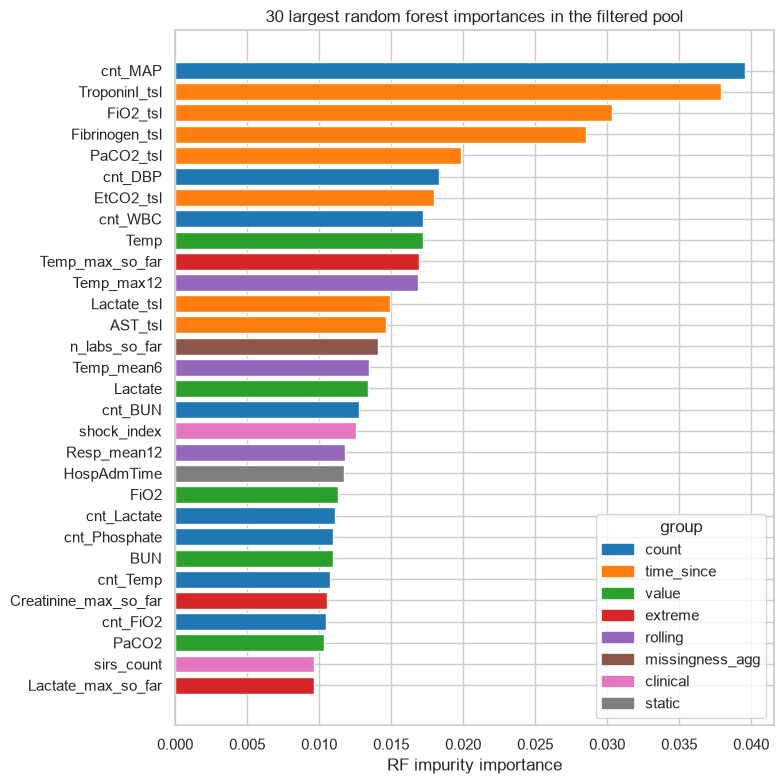

  model  n_features  val_auroc  val_auprc
pool_rf         200      0.837      0.107
core_rf          50      0.828      0.105
core random forest and validation scoring: 19.6 s


In [7]:
need("filtered", "gmap", "amap", "FORCED", "train_idx", "val_idx")
CORE_N = 50
pool_f = filtered


def make_rf():
    return RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=100, max_features="sqrt",
                                  class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)


def fit_rf(Xa, ya):
    rf = make_rf()
    try:
        rf.fit(Xa, ya)
        return rf, None
    except ValueError as e:
        log(f"random forest rejected NaN, using median fill instead ({str(e)[:80]})")
        m = np.nan_to_num(np.nanmedian(Xa, axis=0)).astype(np.float32)
        rf = make_rf()
        rf.fit(fill_nan(Xa, m), ya)
        return rf, m


def rf_scores(rf, m, Xa):
    return rf.predict_proba(Xa if m is None else fill_nan(Xa, m))[:, 1]


with guarded("core feature selection"):
    with timed("pool random forest"):
        Xtr = load_any(pool_f, ROWS300)
        rf_pool, med_pool = fit_rf(Xtr, ys)

    rk = pd.DataFrame({"feature": pool_f})
    rk["group"] = rk["feature"].map(gmap)
    rk["auc"] = rk["feature"].map(amap)
    rk["rf_importance"] = rf_pool.feature_importances_
    rk["rank_auc"] = rk["auc"].rank(ascending=False, method="min")
    rk["rank_rf"] = rk["rf_importance"].rank(ascending=False, method="min")
    rk["mean_rank"] = (rk["rank_auc"] + rk["rank_rf"]) / 2
    rk = rk.sort_values(["mean_rank", "rank_auc", "feature"]).reset_index(drop=True)
    rk["combined_rank"] = np.arange(1, len(rk) + 1)
    rk["forced"] = rk["feature"].isin(FORCED_SET)
    extra = rk.loc[~rk["forced"], "feature"].head(CORE_N - len(FORCED)).tolist()
    core = FORCED + extra
    rk["selected"] = rk["feature"].isin(core)
    rk.drop(columns="mean_rank").to_csv(TAB / "core_feature_ranking.csv", index=False)
    save_json({"core": core, "forced": FORCED}, PROC / "core_features.json")

    rho_ranks = spearmanr(rk["rank_auc"], rk["rank_rf"])[0]
    log(f"Spearman between AUROC rank and RF rank: {rho_ranks:.3f}")
    log("core set by group: " + ", ".join(f"{g} {n}" for g, n in rk.loc[rk["selected"], "group"].value_counts().items()))
    for f in ["ICULOS", "HospAdmTime", "unit_1", "unit_2", "unit_unknown"]:
        state = "selected" if f in core else ("filtered out" if f not in pool_f else "not selected")
        log(f"{f}: {state}")
    log(f"cnt_ features selected: {[f for f in core if f.startswith('cnt_')]}")
    log(f"rate_ features selected: {[f for f in core if f.startswith('rate_')]}")
    print(rk.drop(columns="mean_rank").head(15))

    check("core size between 30 and 60", 30 <= len(core) <= 60, f"{len(core)} features")
    check("all forced features in core", all(f in core for f in FORCED))
    check("no id or target column in core", not (set(core) & set(ID_COLS + [TARGET])))
    check("core names exist in features_flat or rate_features", set(core) <= (set(feats) | RATE_SET))
    check("core has no duplicates", len(set(core)) == len(core))

    top = rk.sort_values("rf_importance", ascending=False).head(30)
    glist = list(dict.fromkeys(top["group"]))
    pal = dict(zip(glist, sns.color_palette("tab10", len(glist))))
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.barh(top["feature"], top["rf_importance"], color=[pal[g] for g in top["group"]])
    ax.invert_yaxis()
    ax.set_xlabel("RF impurity importance")
    ax.set_title("30 largest random forest importances in the filtered pool")
    handles = [plt.Rectangle((0, 0), 1, 1, color=pal[g]) for g in glist]
    ax.legend(handles, glist, title="group", loc="lower right")
    save_fig("fig06_rf_importance_top30.png")

with guarded("pool versus core random forest"):
    with timed("core random forest and validation scoring"):
        core_pos = [pool_f.index(f) for f in core]
        rf_core, med_core = fit_rf(Xtr[:, core_pos], ys)
        Xv = load_any(pool_f, val_idx)
        yv = y[val_idx]
        p_pool = rf_scores(rf_pool, med_pool, Xv)
        p_core = rf_scores(rf_core, med_core, Xv[:, core_pos])
        cmp_df = pd.DataFrame([
            {"model": "pool_rf", "n_features": len(pool_f), "val_auroc": roc_auc_score(yv, p_pool), "val_auprc": average_precision_score(yv, p_pool)},
            {"model": "core_rf", "n_features": len(core), "val_auroc": roc_auc_score(yv, p_core), "val_auprc": average_precision_score(yv, p_core)},
        ])
        cmp_df.to_csv(TAB / "core_vs_pool_rf.csv", index=False)
        print(cmp_df.to_string(index=False))
        del Xv, p_pool, p_core
Xtr = None

## Scaled core table

The core features are filled, log-transformed when very skewed and standardised with parameters fitted on train rows only.

In [8]:
need("core", "train_idx", "val_idx", "test_idx", "ids")

with guarded("scaled core table"):
    with timed("scaled core table"):
        Xc = load_any(core)
        out = np.empty_like(Xc)
        p_med, p_log, p_mean, p_std, p_bin = {}, {}, {}, {}, []
        for j, f in enumerate(core):
            col = Xc[:, j]
            m = np.nanmedian(col[train_idx])
            m = 0.0 if np.isnan(m) else float(m)
            filled = np.where(np.isnan(col), m, col).astype(np.float64)
            tv = filled[train_idx]
            p_med[f] = m
            if set(np.unique(tv).tolist()) <= {0.0, 1.0}:
                p_bin.append(f)
                p_log[f], p_mean[f], p_std[f] = False, 0.0, 1.0
                out[:, j] = filled
                continue
            p_log[f] = bool(abs(skew(tv)) > 3)
            if p_log[f]:
                filled = np.sign(filled) * np.log1p(np.abs(filled))
                tv = filled[train_idx]
            mu, sd = float(tv.mean()), float(tv.std())
            if sd == 0:
                log(f"{f} has zero std on train rows")
                sd = 1.0
            p_mean[f], p_std[f] = mu, sd
            out[:, j] = (filled - mu) / sd
        del Xc
        joblib.dump({"features": core, "medians": p_med, "log1p": p_log, "means": p_mean, "stds": p_std, "binary": p_bin},
                    PROC / "core_scale_params.joblib")
        std_cols = [f for f in core if f not in p_bin]
        log(f"{len(std_cols)} standardised columns, {len(p_bin)} binary columns, {sum(p_log.values())} log1p columns")

        check("no NaN or inf in core_scaled", np.isfinite(out).all())
        worst_m, worst_s = 0.0, 0.0
        for f in std_cols:
            v = out[train_idx, core.index(f)].astype(np.float64)
            worst_m, worst_s = max(worst_m, abs(v.mean())), max(worst_s, abs(v.std() - 1))
        check("train mean within 1e-3 of 0", worst_m <= 1e-3, f"worst {worst_m:.2e}")
        check("train std within 1e-3 of 1", worst_s <= 1e-3, f"worst {worst_s:.2e}")

        frame = make_frame(out, core)
        frame.to_parquet(PROC / "core_scaled.parquet", index=False)
        del frame
        back = pd.read_parquet(PROC / "core_scaled.parquet", columns=["patient_id", "hour"])
        check("core_scaled aligned with features_flat",
              (back["patient_id"].to_numpy() == ids["patient_id"].to_numpy()).all() and (back["hour"].to_numpy() == hour).all())
        del back

        ci = [core.index(f) for f in std_cols]
        shift = pd.DataFrame({"column": std_cols,
                              "val_mean": out[val_idx][:, ci].mean(axis=0), "val_std": out[val_idx][:, ci].std(axis=0),
                              "test_mean": out[test_idx][:, ci].mean(axis=0), "test_std": out[test_idx][:, ci].std(axis=0)})
        shift.to_csv(TAB / "core_scaled_shift_val_test.csv", index=False)
        for part in ("val", "test"):
            s = shift.assign(dev_std=(shift[f"{part}_std"] - 1).abs(), dev_mean=shift[f"{part}_mean"].abs())
            log(f"{part}: largest |std - 1|")
            print(s.nlargest(5, "dev_std")[["column", f"{part}_mean", f"{part}_std"]].to_string(index=False))
            log(f"{part}: largest |mean|")
            print(s.nlargest(5, "dev_mean")[["column", f"{part}_mean", f"{part}_std"]].to_string(index=False))

49 standardised columns, 1 binary columns, 16 log1p columns
[PASS] no NaN or inf in core_scaled
[PASS] train mean within 1e-3 of 0 (worst 1.92e-08)
[PASS] train std within 1e-3 of 1 (worst 2.42e-08)
[PASS] core_scaled aligned with features_flat
val: largest |std - 1|
               column  val_mean  val_std
                  BUN    -0.013    0.943
          Resp_mean12     0.023    1.032
           Resp_min12     0.017    1.028
          cnt_Calcium     0.002    1.028
Creatinine_max_so_far    -0.015    0.973
val: largest |mean|
         column  val_mean  val_std
  HR_max_so_far     0.024    1.014
Resp_max_so_far     0.023    1.017
    Resp_mean12     0.023    1.032
 MAP_min_so_far    -0.020    0.995
        HR_max6     0.020    1.011
test: largest |std - 1|
        column  test_mean  test_std
WBC_max_so_far     -0.001     1.042
         O2Sat     -0.023     1.031
           BUN      0.011     1.029
          FiO2     -0.001     1.021
   Resp_mean12     -0.004     1.018
test: largest |m

## PCA

PCA is fitted on the train rows of the scaled core table and the number of components is the smallest one that keeps 95 percent of the variance.

29 components keep 0.951 of the variance
  component  var_ratio  cumulative
0       PC1      0.261       0.261
1       PC2      0.111       0.372
2       PC3      0.089       0.461
3       PC4      0.074       0.535
4       PC5      0.065       0.600
5       PC6      0.056       0.656
6       PC7      0.033       0.689
7       PC8      0.028       0.717
8       PC9      0.025       0.742
9      PC10      0.021       0.763
  component        feature  loading  abs_loading
0       PC1        cnt_BUN    0.244        0.244
1       PC1        cnt_MAP    0.242        0.242
2       PC1        cnt_WBC    0.239        0.239
3       PC1  n_labs_so_far    0.239        0.239
4       PC1  TroponinI_tsl    0.236        0.236
5       PC1  cnt_Magnesium    0.235        0.235
6       PC1        cnt_Hct    0.234        0.234
7       PC1       cnt_Temp    0.227        0.227
8       PC2             HR    0.316        0.316
9       PC2       HR_min12    0.314        0.314
[PASS] pca scores aligned with feat

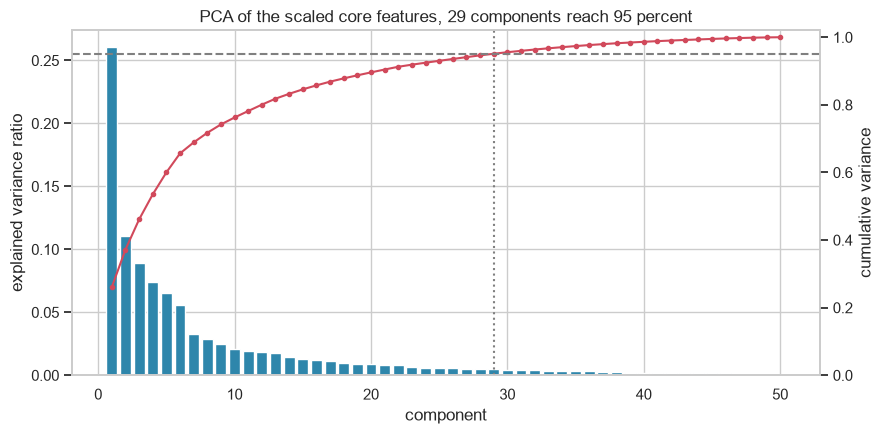

pca: 1.3 s


In [9]:
need("out", "core", "train_idx")

with guarded("pca"):
    with timed("pca"):
        Xt = out[train_idx]
        pca_full = PCA(random_state=SEED).fit(Xt)
        cum_full = np.cumsum(pca_full.explained_variance_ratio_)
        k = int(np.argmax(cum_full >= 0.95) + 1)
        pca = PCA(n_components=k, random_state=SEED).fit(Xt)
        del Xt
        log(f"{k} components keep {cum_full[k - 1]:.3f} of the variance")
        pc_names = [f"PC{i + 1}" for i in range(k)]
        joblib.dump({"pca": pca, "features": core, "n_components": k}, PROC / "core_pca.joblib")

        var_df = pd.DataFrame({"component": [f"PC{i + 1}" for i in range(len(cum_full))],
                               "var_ratio": pca_full.explained_variance_ratio_, "cumulative": cum_full})
        var_df.to_csv(TAB / "pca_variance.csv", index=False)
        print(var_df.head(10))

        load_rows = []
        for i in range(min(3, k)):
            comp = pca.components_[i]
            for j in np.argsort(-np.abs(comp))[:8]:
                load_rows.append({"component": f"PC{i + 1}", "feature": core[j], "loading": comp[j], "abs_loading": abs(comp[j])})
        load_df = pd.DataFrame(load_rows)
        load_df.to_csv(TAB / "pca_top_loadings.csv", index=False)
        print(load_df.head(10))

        Z = pca.transform(out).astype(np.float32)
        frame = make_frame(Z, pc_names)
        frame.to_parquet(PROC / "pca_scores.parquet", index=False)
        del frame
        back = pd.read_parquet(PROC / "pca_scores.parquet", columns=["patient_id", "hour"])
        check("pca scores aligned with features_flat",
              (back["patient_id"].to_numpy() == ids["patient_id"].to_numpy()).all() and (back["hour"].to_numpy() == hour).all())
        del back

        expect("pca.n_samples_ equals train row count", int(pca.n_samples_), len(train_idx))
        expect("train rows", len(train_idx), 1085958)
        check("cumulative explained variance at least 0.95", pca.explained_variance_ratio_.sum() >= 0.95,
              f"{pca.explained_variance_ratio_.sum():.4f}")

        fig, ax = plt.subplots(figsize=(9, 4.5))
        xs = np.arange(1, len(cum_full) + 1)
        ax.bar(xs, pca_full.explained_variance_ratio_, color=C_CTL)
        ax.set_xlabel("component")
        ax.set_ylabel("explained variance ratio")
        ax2 = ax.twinx()
        ax2.plot(xs, cum_full, color=C_SEP, marker="o", markersize=3)
        ax2.axhline(0.95, color="grey", linestyle="--")
        ax2.axvline(k, color="grey", linestyle=":")
        ax2.set_ylabel("cumulative variance")
        ax2.set_ylim(0, 1.02)
        ax2.grid(False)
        ax.set_title(f"PCA of the scaled core features, {k} components reach 95 percent")
        save_fig("fig06_pca_variance.png")
        del pca_full

## Fixed training subset for KNN and SVM

The subset has every positive train row and enough random negative train rows to reach exactly 100,000 rows.

In [10]:
need("out", "Z", "pc_names", "core", "train_idx")

with guarded("training subset"):
    pos_rows = train_idx[y[train_idx] == 1]
    neg_rows = train_idx[y[train_idx] == 0]
    n_neg = 100000 - len(pos_rows)
    if n_neg <= 0 or n_neg > len(neg_rows):
        raise ValueError(f"cannot fill subset, {len(pos_rows)} positives")
    rng = np.random.default_rng(SEED)
    sub = np.sort(np.concatenate([pos_rows, rng.choice(neg_rows, size=n_neg, replace=False)]))

    idx_df = pd.DataFrame({"row_index": sub, "patient_id": ids["patient_id"].to_numpy()[sub],
                           "hour": hour[sub], "SepsisLabel": y[sub]})
    idx_df.to_parquet(PROC / "train_subset_index.parquet", index=False)
    make_frame(out, core, sub).to_parquet(PROC / "train_subset_core_scaled.parquet", index=False)
    make_frame(Z, pc_names, sub).to_parquet(PROC / "train_subset_pca.parquet", index=False)

    by_split = sp.groupby("split")[["n_positive_rows", "n_rows"]].sum()
    rate_of = (by_split["n_positive_rows"] / by_split["n_rows"]).to_dict()
    share = float(y[sub].mean())
    summ = pd.DataFrame({"metric": ["subset_rows", "subset_positives", "subset_positive_share", "subset_distinct_patients",
                                    "subset_septic_patients", "train_positive_rate", "val_positive_rate", "test_positive_rate"],
                         "value": [len(sub), int(y[sub].sum()), share, idx_df["patient_id"].nunique(),
                                   idx_df.loc[idx_df["SepsisLabel"] == 1, "patient_id"].nunique(),
                                   rate_of["train"], rate_of["val"], rate_of["test"]]})
    summ.to_csv(TAB / "subset_summary.csv", index=False)
    print(summ.to_string(index=False))

    check("every subset row is a train row", (split_arr[sub] == "train").all())
    check("every train positive row is in the subset", np.isin(pos_rows, sub).all())
    check("no duplicate row_index", len(np.unique(sub)) == len(sub))
    expect("subset size", len(sub), 100000)
    log(f"subset positive share {share:.3f} against {rate_of['train']:.4f} in the full train rows, "
        "so probabilities from models trained on it are not calibrated and thresholds must be chosen on the full validation rows")

                  metric      value
             subset_rows 100000.000
        subset_positives  19530.000
   subset_positive_share      0.195
subset_distinct_patients  25710.000
  subset_septic_patients   2052.000
     train_positive_rate      0.018
       val_positive_rate      0.018
      test_positive_rate      0.018
[PASS] every subset row is a train row
[PASS] every train positive row is in the subset
[PASS] no duplicate row_index
[PASS] subset size (observed 100000, expected 100000)
subset positive share 0.195 against 0.0180 in the full train rows, so probabilities from models trained on it are not calibrated and thresholds must be chosen on the full validation rows


## Feature sets for the ablations

This section extends feature_sets.json with the count, rate, core and PCA sets used in the later ablations.

In [11]:
need("core", "pc_names", "feature_sets")

with guarded("feature sets v2"):
    base_all = list(feature_sets["all"])
    cnt_cols = cnt_cols_v + ["n_labs_so_far"]
    cnt_set = set(cnt_cols)
    sets_v2 = dict(feature_sets)
    sets_v2["cnt_cols"] = cnt_cols
    sets_v2["rate_cols"] = list(rate_cols)
    sets_v2["all_plus_rates"] = base_all + rate_cols
    sets_v2["with_counts"] = list(base_all)
    sets_v2["with_rates"] = [f for f in base_all if f not in cnt_set] + rate_cols
    sets_v2["no_counts_no_rates"] = [f for f in base_all if f not in cnt_set]
    sets_v2["core"] = list(core)
    sets_v2["core_no_icu_time"] = [f for f in core if f not in ("ICULOS", "HospAdmTime")]
    sets_v2["masks_only"] = [f"{c}_m" for c in VALUE_COLS]
    sets_v2["pca_cols"] = list(pc_names)
    save_json(sets_v2, PROC / "feature_sets_v2.json")
    for name, members in sets_v2.items():
        log(f"{name}: {len(members)}")

    universe = set(all_cols) | RATE_SET
    bad = {n: [f for f in m if f not in universe] for n, m in sets_v2.items() if n != "pca_cols"}
    bad = {n: v for n, v in bad.items() if v}
    check("every set member exists in features_flat or rate_features", not bad, str({n: v[:3] for n, v in bad.items()}) if bad else "")
    pca_cols_saved = set(pq.ParquetFile(PROC / "pca_scores.parquet").schema_arrow.names)
    check("pca_cols exist in pca_scores", set(pc_names) <= pca_cols_saved)
    check("count and rate sets share no feature", not (cnt_set & RATE_SET))
    check("with_rates has no count columns and no_counts_no_rates has no rate columns",
          not (set(sets_v2["with_rates"]) & cnt_set) and not (set(sets_v2["no_counts_no_rates"]) & RATE_SET))

all: 239
no_missingness: 134
no_icu_time: 237
vitals_only: 123
raw_values: 41
raw_values_with_missingness: 109
cnt_cols: 35
rate_cols: 35
all_plus_rates: 274
with_counts: 239
with_rates: 239
no_counts_no_rates: 204
core: 50
core_no_icu_time: 50
masks_only: 34
pca_cols: 29
[PASS] every set member exists in features_flat or rate_features
[PASS] pca_cols exist in pca_scores
[PASS] count and rate sets share no feature
[PASS] with_rates has no count columns and no_counts_no_rates has no rate columns


## Output files

The last cell lists every file written by this notebook and stores the log in results.

In [12]:
outputs = [PROC / n for n in ["rate_features.parquet", "filtered_features.json", "core_features.json", "core_scaled.parquet",
                              "core_scale_params.joblib", "core_pca.joblib", "pca_scores.parquet", "train_subset_index.parquet",
                              "train_subset_core_scaled.parquet", "train_subset_pca.parquet", "feature_sets_v2.json"]]
outputs += [TAB / n for n in ["rate_vs_count_auroc.csv", "count_vs_rate_by_hour_bin.csv", "correlation_spearman_features.csv",
                              "redundancy_drops.csv", "feature_group_counts_by_stage.csv", "core_feature_ranking.csv",
                              "core_vs_pool_rf.csv", "core_scaled_shift_val_test.csv", "pca_variance.csv",
                              "pca_top_loadings.csv", "subset_summary.csv"]]
outputs += [FIG / n for n in ["fig06_count_vs_rate.png", "fig06_group_counts.png", "fig06_rf_importance_top30.png", "fig06_pca_variance.png"]]

n_missing = 0
for p in outputs:
    if p.exists():
        log(f"{p.relative_to(ROOT)}  {p.stat().st_size / 1e6:.2f} MB")
    else:
        n_missing += 1
        log(f"{p.relative_to(ROOT)}  MISSING")
check("all expected output files exist", n_missing == 0, f"{n_missing} missing")

log(f"checks: {COUNTS['pass']} passed, {COUNTS['fail']} failed")
summary_path = ROOT / "results" / "step06_summary.txt"
summary_path.write_text("\n".join(SUMMARY) + "\n")
print(summary_path)

data/processed/rate_features.parquet  28.04 MB
data/processed/filtered_features.json  0.00 MB
data/processed/core_features.json  0.00 MB
data/processed/core_scaled.parquet  37.56 MB
data/processed/core_scale_params.joblib  0.00 MB
data/processed/core_pca.joblib  0.01 MB
data/processed/pca_scores.parquet  213.46 MB
data/processed/train_subset_index.parquet  1.00 MB
data/processed/train_subset_core_scaled.parquet  4.80 MB
data/processed/train_subset_pca.parquet  17.76 MB
data/processed/feature_sets_v2.json  0.03 MB
results/tables/rate_vs_count_auroc.csv  0.00 MB
results/tables/count_vs_rate_by_hour_bin.csv  0.00 MB
results/tables/correlation_spearman_features.csv  0.48 MB
results/tables/redundancy_drops.csv  0.00 MB
results/tables/feature_group_counts_by_stage.csv  0.00 MB
results/tables/core_feature_ranking.csv  0.01 MB
results/tables/core_vs_pool_rf.csv  0.00 MB
results/tables/core_scaled_shift_val_test.csv  0.00 MB
results/tables/pca_variance.csv  0.00 MB
results/tables/pca_top_loadin